# 01 · Exploratory analysis

**Question for this notebook:** what in the data is associated with 30-day
readmission, where are the traps, and what does that mean for feature design?

**Ground rule:** this notebook uses the **training set only**. The patient-disjoint
test set (20%) was split off before any exploration (`readmission_risk.data.split`)
and is not opened until final evaluation, so nothing seen here can leak into the
test result.

Reusable logic lives in `src/readmission_risk/` and is unit-tested; this notebook
is the narrative.

In [1]:
import pandas as pd
from IPython.display import display

from readmission_risk.analysis import (
    chi_square_independence,
    missingness,
    rate_table,
)
from readmission_risk.config import PROJECT_ROOT
from readmission_risk.data.clean import GROUP_COL, TARGET
from readmission_risk.visualisation.plots import (
    apply_style,
    plot_missingness,
    plot_rates,
    save,
)

apply_style()
pd.set_option("display.precision", 3)
FIGURES = PROJECT_ROOT / "reports" / "figures"

train = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
overall = train[TARGET].mean()
print(f"{len(train):,} encounters · {train[GROUP_COL].nunique():,} patients")
print(f"Readmitted within 30 days: {overall:.2%}")

79,473 encounters · 56,036 patients
Readmitted within 30 days: 11.39%


## 1. Outcome balance

About **11.4%** of encounters are readmitted within 30 days. With roughly 1 positive
in 9, accuracy is meaningless (predicting "no" for everyone scores ~89%). The project
therefore uses **PR-AUC** as its primary metric, plus calibration.

## 2. Missing data

,share_missing
medical_specialty,4.894e-01
payer_code,3.957e-01
admission_type,1.031e-01
admission_source,6.967e-02
discharge_disposition,4.719e-02
race,2.226e-02
diag_3,1.432e-02
diag_2,3.649e-03
diag_1,1.762e-04


PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_missingness.png')

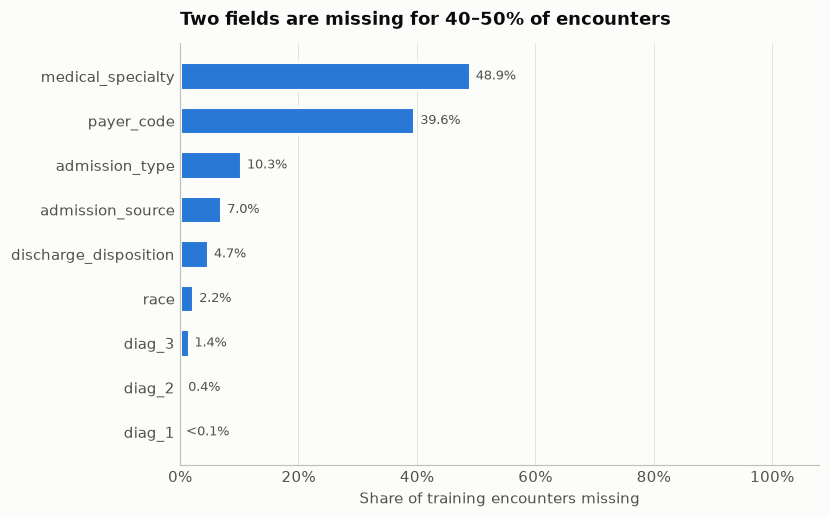

In [2]:
miss = missingness(train)
display(miss.to_frame("share_missing"))
ax = plot_missingness(miss, "Two fields are missing for 40–50% of encounters")
save(ax.figure, FIGURES / "eda_missingness.png")

In [3]:
for col in ["medical_specialty", "payer_code", "race"]:
    t = rate_table(train, col)
    print(
        f"{col:18s} readmission when missing: {t.loc['Missing', 'rate']:.1%}  "
        f"(overall {overall:.1%})"
    )

medical_specialty  readmission when missing: 11.9%  (overall 11.4%)
payer_code         readmission when missing: 11.8%  (overall 11.4%)
race               readmission when missing: 8.5%  (overall 11.4%)


**Decision:** `medical_specialty` and `payer_code` are missing so often that
imputing a "most likely" value would invent data. Missingness is kept as its own
category ("Missing"). Missing `race` has a *lower* readmission rate, which hints
that recording practices differ between hospitals. That is a reminder that the
data reflects processes as well as patients.

## 3. Prior utilisation: the strongest signal

,n,events,rate,ci_low,ci_high
prior_inpatient,,,,,
0,53065,4563,0.086,0.084,0.088
1,15156,1996,0.132,0.126,0.137
2,5798,1050,0.181,0.171,0.191
3,2603,552,0.212,0.197,0.228
4,1272,310,0.244,0.221,0.268
5+,1579,580,0.367,0.344,0.391


{'chi2': 2182.4174790556626,
 'dof': 5,
 'p_value': 0.0,
 'cramers_v': 0.16571396624008347}

PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_prior_inpatient.png')

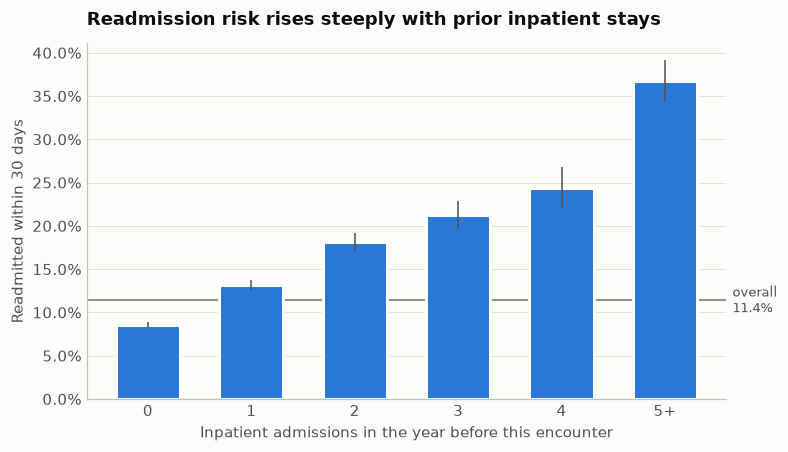

In [4]:
train["prior_inpatient"] = (
    train["number_inpatient"].clip(upper=5).astype(str).replace("5", "5+")
)
t = rate_table(train, "prior_inpatient")
display(t)
display(chi_square_independence(train, "prior_inpatient"))
ax = plot_rates(
    t,
    "Readmission risk rises steeply with prior inpatient stays",
    overall,
    xlabel="Inpatient admissions in the year before this encounter",
)
save(ax.figure, FIGURES / "eda_prior_inpatient.png")

Patients with no prior admissions are readmitted about **8.6%** of the time; with
five or more, about **37%**. This is the largest association in the dataset
(Cramér's V ≈ 0.17). `number_inpatient` counts visits *before* the encounter, so it
is legitimately available at discharge.

## 4. A leakage trap: "how many times is this patient in the data?"

,n,events,rate,ci_low,ci_high
encounters_in_dataset,,,,,
1,42959,1845,0.043,0.041,0.045
2,16398,2496,0.152,0.147,0.158
3,7773,1503,0.193,0.185,0.202
4,4292,919,0.214,0.202,0.227
5+,8051,2288,0.284,0.274,0.294


PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_leakage_trap.png')

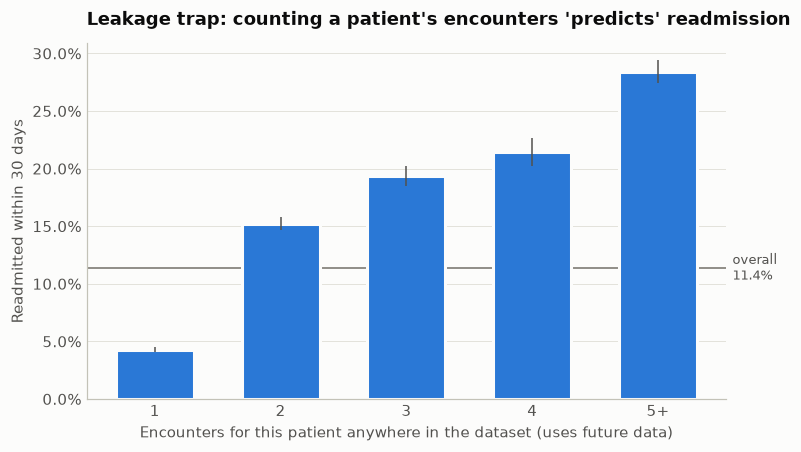

In [5]:
train["encounters_in_dataset"] = (
    train.groupby(GROUP_COL)["encounter_id"]
    .transform("size")
    .clip(upper=5)
    .astype(str)
    .replace("5", "5+")
)
t = rate_table(train, "encounters_in_dataset")
display(t)
ax = plot_rates(
    t,
    "Leakage trap: counting a patient's encounters 'predicts' readmission",
    overall,
    xlabel="Encounters for this patient anywhere in the dataset (uses future data)",
)
save(ax.figure, FIGURES / "eda_leakage_trap.png")

Patients who appear once have a ~4% readmission rate; those who appear five or
more times, ~28%. This looks like a superb feature and is **pure leakage**: a
readmission *is* another encounter in the dataset, so the count partly contains the
answer, and it uses visits that happen after discharge.

**Decisions:**
- Never build features from a patient's other rows in the dataset. Use only the
  pre-encounter counts the data provides (`number_inpatient`, `number_emergency`,
  `number_outpatient`).
- This is also why every split is grouped by patient. With a random split, the
  model would learn patient identity from repeat visits.

## 5. Where patients go after discharge

,n,events,rate,ci_low,ci_high
Rehab facility,1592,442,0.278,0.256,0.300
Other inpatient care,949,201,0.212,0.187,0.239
Another short-term hospital,1683,264,0.157,0.140,0.175
Skilled nursing facility,11119,1635,0.147,0.141,0.154
Left against medical advice,505,74,0.147,0.118,0.180
Home with home health,10314,1306,0.127,0.120,0.133
Intermediate care facility,663,82,0.124,0.101,0.151
Missing,3750,458,0.122,0.112,0.133
Home,48241,4481,0.093,0.090,0.096
Long-term care hospital,321,21,0.065,0.043,0.098


{'chi2': 1075.5565959721857,
 'dof': 19,
 'p_value': 3.85721252628591e-216,
 'cramers_v': 0.11633404534454689}

PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_discharge.png')

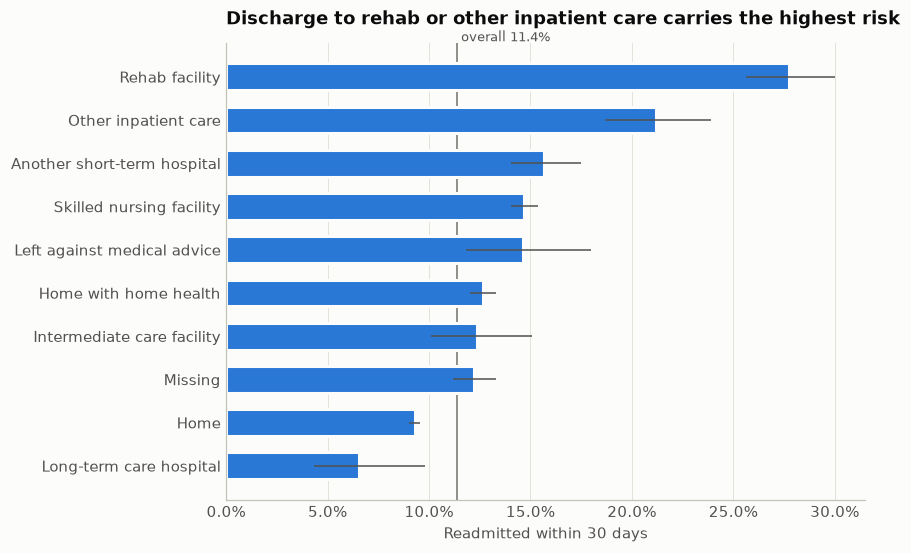

In [6]:
# Short display names for the official (long) disposition labels.
SHORT = {
    "Discharged to home": "Home",
    "Discharged/transferred to home with home health service": "Home with home health",
    "Discharged/transferred to SNF": "Skilled nursing facility",
    "Discharged/transferred to ICF": "Intermediate care facility",
    "Discharged/transferred to another short term hospital": "Another short-term hospital",
    "Discharged/transferred to another rehab fac including rehab units of a hospital .": "Rehab facility",
    "Discharged/transferred to another type of inpatient care institution": "Other inpatient care",
    "Discharged/transferred to a long term care hospital.": "Long-term care hospital",
    "Left AMA": "Left against medical advice",
}
t = rate_table(train, "discharge_disposition", min_count=300)
t.index = [SHORT.get(s, s) for s in t.index]
t = t.sort_values("rate", ascending=False)
display(t)
display(chi_square_independence(train, "discharge_disposition"))
ax = plot_rates(
    t,
    "Discharge to rehab or other inpatient care carries the highest risk",
    overall,
    horizontal=True,
)
save(ax.figure, FIGURES / "eda_discharge.png")

Patients discharged home have the lowest risk. Those transferred to rehab, other
inpatient care or a skilled nursing facility have markedly higher risk. These are
sicker patients, so discharge destination works as a proxy for severity. Because
it's known at discharge, it is a valid input.

## 6. Age

,n,events,rate,ci_low,ci_high
0–9,125,3,0.024,0.008,0.068
10–19,576,33,0.057,0.041,0.079
20–29,1337,207,0.155,0.136,0.175
30–39,3011,331,0.110,0.099,0.122
40–49,7704,869,0.113,0.106,0.120
50–59,13634,1289,0.095,0.090,0.100
60–69,17553,1987,0.113,0.109,0.118
70–79,20318,2450,0.121,0.116,0.125
80–89,13171,1658,0.126,0.120,0.132
90–99,2044,224,0.110,0.097,0.124


PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_age.png')

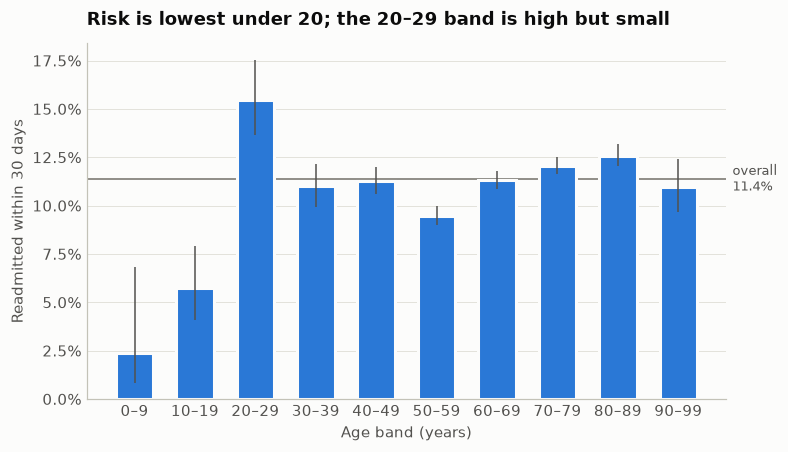

In [7]:
t = rate_table(train, "age")
t.index = [
    f"{band[1:-1].split('-')[0]}–{int(band[1:-1].split('-')[1]) - 1}"
    for band in t.index
]
display(t)
ax = plot_rates(
    t,
    "Risk is lowest under 20; the 20–29 band is high but small",
    overall,
    xlabel="Age band (years)",
)
save(ax.figure, FIGURES / "eda_age.png")

The under-20 bands are small (wide intervals). The 20–29 band has the highest rate
(about 15.5%), but it rests on only about 1,300 encounters, so treat it with care.
Among the large bands, risk is lowest at 50–59 and highest at 70–89. Age is kept as an **ordinal** feature (band
order preserved) instead of 10 unrelated categories.

## 7. HbA1c testing: the original study's question

,n,events,rate,ci_low,ci_high
A1Cresult,,,,,
Norm,3942,390,0.099,0.090,0.109
>7,3021,309,0.102,0.092,0.114
>8,6549,662,0.101,0.094,0.109
Not measured,65961,7690,0.117,0.114,0.119


{'chi2': 28.154948653728283,
 'dof': 3,
 'p_value': 3.369957968583028e-06,
 'cramers_v': 0.018822077883526536}

PosixPath('/home/vboxuser/projects/github/readmission-risk-model/reports/figures/eda_a1c.png')

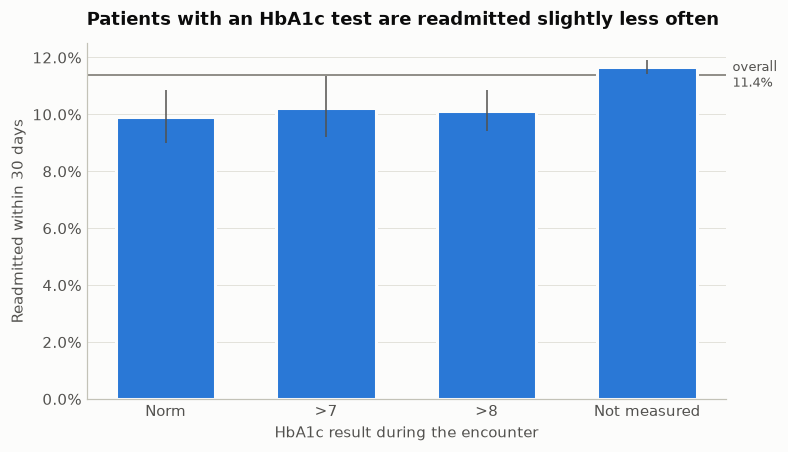

In [8]:
t = rate_table(train, "A1Cresult").loc[["Norm", ">7", ">8", "Not measured"]]
display(t)
display(chi_square_independence(train, "A1Cresult"))
ax = plot_rates(
    t,
    "Patients with an HbA1c test are readmitted slightly less often",
    overall,
    xlabel="HbA1c result during the encounter",
)
save(ax.figure, FIGURES / "eda_a1c.png")

Encounters with any HbA1c result are readmitted at about 10%, against about 11.7%
when it was not measured. The difference is statistically significant but
**small** (Cramér's V ≈ 0.02). With 80,000 rows, almost any difference reaches
significance, so effect sizes are reported alongside p-values. This is
association, not causation: patients who get tested may also differ in other
ways.

## 8. Sex and race: fairness preview

In [9]:
for col in ["gender", "race"]:
    display(rate_table(train, col))
    display(chi_square_independence(train, col))

,n,events,rate,ci_low,ci_high
gender,,,,,
Female,42923,4921,0.115,0.112,0.118
Male,36550,4130,0.113,0.110,0.116


{'chi2': 0.5171280038592674,
 'dof': 1,
 'p_value': 0.47206937162890894,
 'cramers_v': 0.0025508752768525446}

,n,events,rate,ci_low,ci_high
race,,,,,
AfricanAmerican,15014,1742,0.116,0.111,0.121
Asian,514,54,0.105,0.081,0.135
Caucasian,59394,6825,0.115,0.112,0.118
Hispanic,1639,169,0.103,0.089,0.119
Missing,1769,151,0.085,0.073,0.099
Other,1143,110,0.096,0.080,0.115


{'chi2': 21.373510419434297,
 'dof': 5,
 'p_value': 0.0006884412219182209,
 'cramers_v': 0.01639940626844993}

Readmission rates barely differ by sex (p ≈ 0.47) and differ only slightly by
race. That doesn't make a model fair. Error rates and calibration can still vary
across groups, so the fairness audit in step 6 checks model performance for each
group, not just base rates. Whether `race` should be a model input at all is
tested explicitly in modelling.

## 9. Diagnoses need grouping

In [10]:
for col in ["diag_1", "diag_2", "diag_3"]:
    print(f"{col}: {train[col].nunique()} distinct ICD-9 codes")
display(train["diag_1"].value_counts().head(10).to_frame("encounters"))

diag_1: 696 distinct ICD-9 codes
diag_2: 712 distinct ICD-9 codes
diag_3: 763 distinct ICD-9 codes


,encounters
diag_1,
428,5285
414,5267
786,3213
410,2748
486,2683
427,2161
491,1777
715,1712
682,1643


Primary diagnosis alone has about 700 distinct ICD-9 codes. Most are rare, which
makes them noisy as raw categories. **Step 4 (your exercise)** groups codes into
clinically meaningful chapters (circulatory, respiratory, diabetes, …).

## 10. Summary: what this means for modelling

| Finding | Decision |
|---|---|
| 11.4% positive rate | PR-AUC primary, calibration checked, threshold set by capacity |
| `medical_specialty` / `payer_code` 40–50% missing | Keep "Missing" as a category; no invented values |
| Prior inpatient stays: strongest signal (8.6% → 37%) | Keep pre-encounter utilisation counts, capped for robustness |
| Patient encounter count is a leak | Never derive features from a patient's other rows; split by patient |
| Discharge destination informative | Keep as categorical, rare levels grouped |
| Age: ordered bands | Ordinal encoding |
| HbA1c effect small | Keep, but expect little lift from it |
| ~700 diagnosis codes | Group into ICD-9 chapters (step 4) |
| All single-variable associations are weak (max V ≈ 0.17) | Expect modest discrimination, and report it honestly |